# Figure 1: Lower convex hull

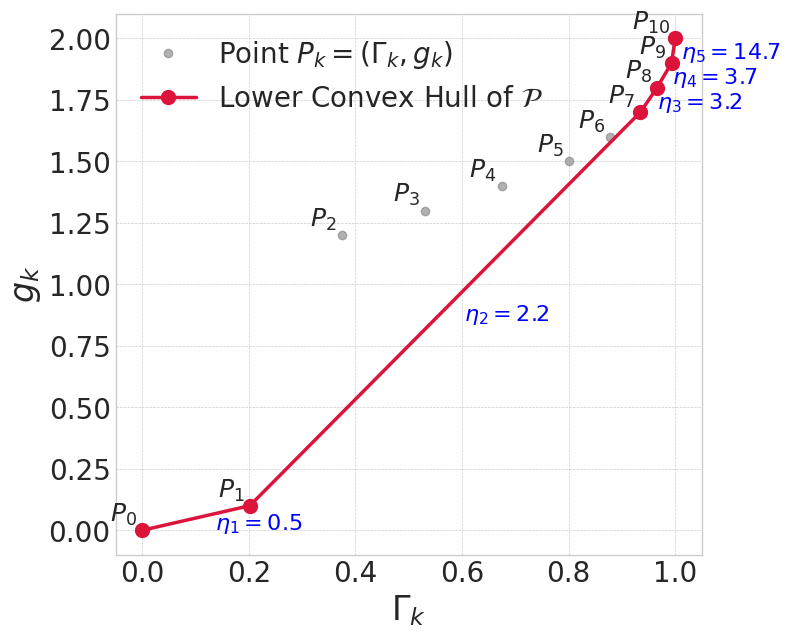

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def g(k, lambda_param):
    """Computes g(F_k) = 1(k>1) + λk."""
    if k == 0:
        return 0.0
    return (1.0 if k > 1 else 0.0) + lambda_param * k

def compute_lower_convex_hull(points):
    """Lower convex hull using Monotone Chain algorithm."""
    lower_hull_indices = []
    for i in range(len(points)):
        while len(lower_hull_indices) >= 2:
            j1, j2 = lower_hull_indices[-2], lower_hull_indices[-1]
            cross_product = (points[j2, 0] - points[j1, 0]) * (points[i, 1] - points[j1, 1]) - \
                            (points[j2, 1] - points[j1, 1]) * (points[i, 0] - points[j1, 0])
            if cross_product <= 1e-9:
                lower_hull_indices.pop()
            else:
                break
        lower_hull_indices.append(i)
    return lower_hull_indices

def primal_visualization(probs, lambda_param):
    """
    Plot the primal space (Γ_k, g_k) with convex hull and labels.
    η_i labels are placed mainly below each hull edge (slightly to the right),
    using ax.annotate so the arrow always follows the label.
    """

    K = len(probs)
    Gamma = np.concatenate(([0], np.cumsum(probs)))
    g_k = np.array([g(k, lambda_param) for k in range(K + 1)])
    points = np.vstack((Gamma, g_k)).T
    hull_indices = compute_lower_convex_hull(points)
    hull_points = points[hull_indices]

    fig, ax = plt.subplots(figsize=(8, 6.5))
    plt.style.use('seaborn-v0_8-whitegrid')

    ax.plot(points[:, 0], points[:, 1], 'o', color='gray', markersize=6, alpha=0.6,
            label='Point $P_k = (\\Gamma_k, g_k)$')
    ax.plot(hull_points[:, 0], hull_points[:, 1], 'o-', color='crimson',
            linewidth=2.5, markersize=10, label='Lower Convex Hull of $\\mathcal{P}$')

    for i in range(K + 1):
        fontweight = 'bold' if i in hull_indices else 'normal'
        ax.text(points[i, 0] - 0.01,
                points[i, 1] + 0.01,
                f'$P_{{{i}}}$',
                ha='right', va='bottom',
                fontsize=18, fontweight=fontweight)
        
    x_range = np.ptp(points[:, 0])
    y_range = np.ptp(points[:, 1])
    for i in range(len(hull_indices) - 1):
        p1, p2 = points[hull_indices[i]], points[hull_indices[i+1]]
        mid = (p1 + p2) / 2.0
        eta = (p2[1] - p1[1]) / (p2[0] - p1[0])

        if i < 2:
            text_pos = (mid[0] + 0.035 * x_range,
                        mid[1] - 0.012 * y_range)
        else:
            text_pos = (mid[0] + 0.015 * x_range,  
                        mid[1] - 0.005 * y_range) 

        ax.text(text_pos[0], text_pos[1],
                f'$\\eta_{{{i+1}}}={eta:.1f}$',
                fontsize=16, color='blue',
                ha='left', va='center') 

    ax.set_xlabel('$\\Gamma_k$', fontsize=24)
    ax.set_ylabel('$g_k$', fontsize=24)
    ax.legend(fontsize=20, loc='upper left')
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=20)

    plt.tight_layout()
    plt.show()
    #fig.savefig("lower_convex_hull.pdf")

# --- Example run ---
if __name__ == "__main__":
    K = 10
    np.random.seed(43)
    probs = np.sort(np.random.rand(K))[::-1]
    probs /= probs.sum()
    primal_visualization(probs, lambda_param=0.1)


# Figure 2: Effect of $\lambda$

Knee point (P(Size>1)) = 0.3206, Corresponding Avg Size = 3.0015


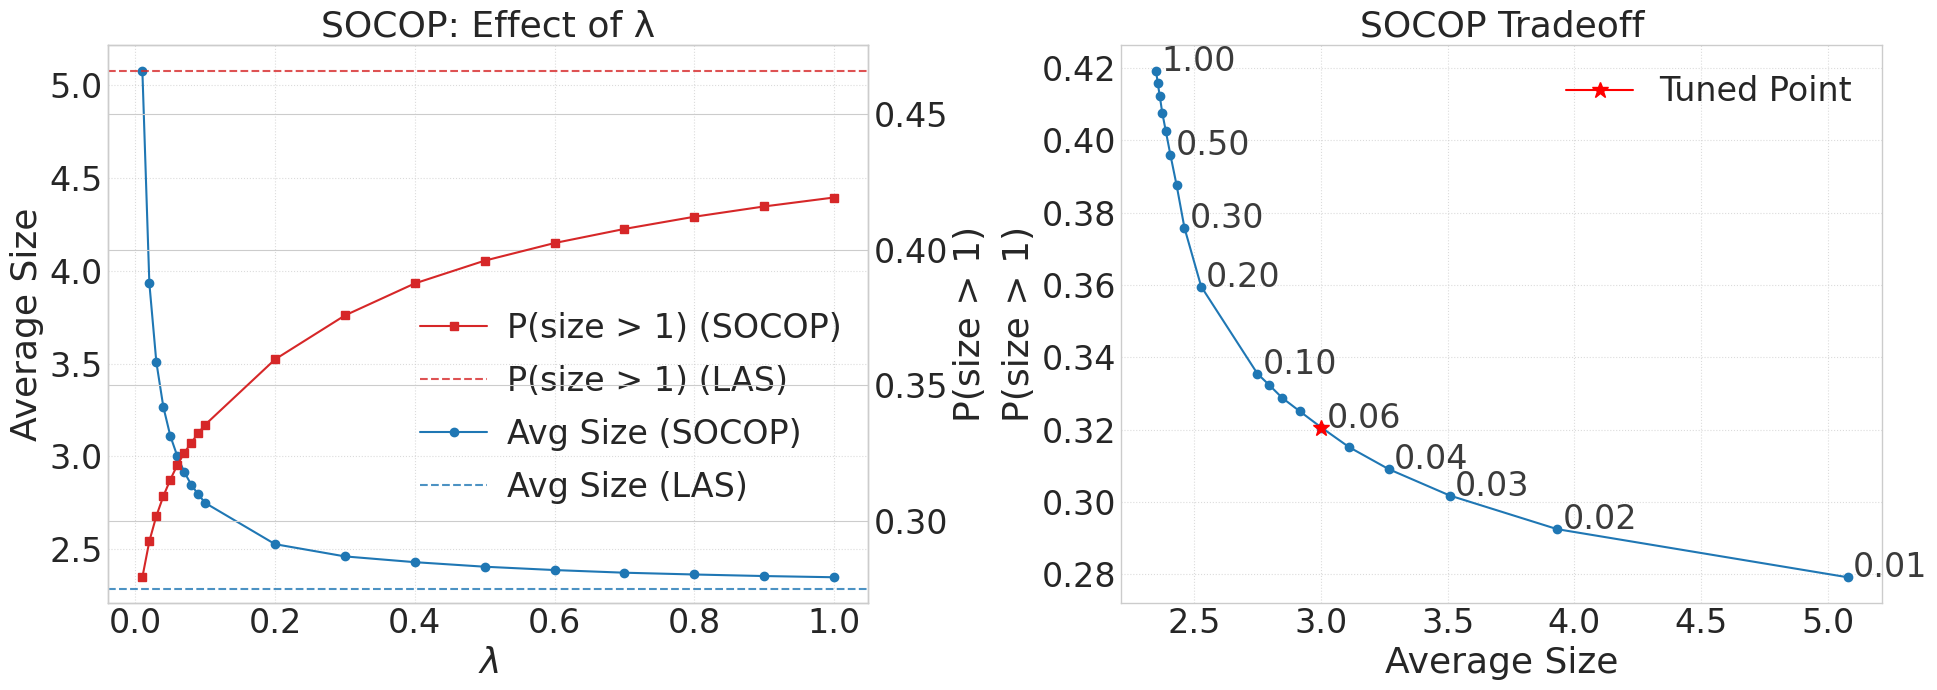

In [8]:
from kneed import KneeLocator
import matplotlib.pyplot as plt

# ---------------------------
# Data from experiments
# ---------------------------
lambdas = [
    0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10,
    0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00
]
avg_size = [
    5.0781, 3.9322, 3.5081, 3.2671, 3.1104, 3.0015, 2.9161, 2.8470, 2.7950, 2.7490,
    2.5270, 2.4611, 2.4301, 2.4056, 2.3876, 2.3733, 2.3637, 2.3553, 2.3488
]
p_size_gt1 = [
    0.2792, 0.2925, 0.3018, 0.3091, 0.3152, 0.3206, 0.3251, 0.3288, 0.3324, 0.3355,
    0.3596, 0.3758, 0.3876, 0.3960, 0.4025, 0.4077, 0.4122, 0.4160, 0.4193
]

limit_avg_size = 2.2831
limit_p_size_gt1 = 0.4661

# Knee
kneedle = KneeLocator(p_size_gt1, avg_size, curve="convex", direction="decreasing")
print(f"Knee point (P(Size>1)) = {kneedle.knee}, Corresponding Avg Size = {kneedle.knee_y}")

# ---------------------------
# Plot
# ---------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(19.5, 7))

ax1.set_title("SOCOP: Effect of λ", fontsize=26)
ax1.set_xlabel(r'$\lambda$', fontsize=26)
ax1.set_ylabel("Average Size", fontsize=26)
line1, = ax1.plot(lambdas, avg_size, marker='o', label="Avg Size (SOCOP)", color='tab:blue')
hline1 = ax1.axhline(y=limit_avg_size, linestyle='--', color='tab:blue',
                     label="Avg Size (LAS)", alpha=0.8)
ax1.grid(True, linestyle=':', linewidth=0.8, alpha=0.7)

ax1b = ax1.twinx()
ax1b.set_ylabel("P(size > 1)", fontsize=26)
line2, = ax1b.plot(lambdas, p_size_gt1, marker='s', label="P(size > 1) (SOCOP)", color='tab:red')
hline2 = ax1b.axhline(y=limit_p_size_gt1, linestyle='--', color='tab:red',
                      label="P(size > 1) (LAS)", alpha=0.8)

handles_red, labels_red = ax1b.get_legend_handles_labels()
handles_blue, labels_blue = ax1.get_legend_handles_labels()
handles = handles_red + handles_blue
labels = labels_red + labels_blue

ax1.legend(handles, labels,
           loc="center right",
           bbox_to_anchor=(1, 0.35),  
           frameon=False,
           fontsize=24,
           borderaxespad=0.4, handletextpad=0.6, labelspacing=0.6)

ax1.tick_params(axis='both', labelsize=24)
ax1b.tick_params(axis='both', labelsize=24)
ax2.set_title("SOCOP Tradeoff", fontsize=26)
ax2.set_xlabel("Average Size", fontsize=26)
ax2.set_ylabel("P(size > 1)", fontsize=26)
ax2.plot(avg_size, p_size_gt1, marker='o', linestyle='-')

highlight_lambdas = {0.01, 0.02, 0.03, 0.04, 0.06, 0.10, 0.20, 0.30, 0.50, 1.00}
for x, y, lam in zip(avg_size, p_size_gt1, lambdas):
    if lam in highlight_lambdas:
        ax2.text(x + 0.02, y, f"{lam:.2f}", fontsize=24, alpha=0.9)

if kneedle.knee is not None and kneedle.knee_y is not None:
    knee_x, knee_y = kneedle.knee_y, kneedle.knee
    ax2.plot(knee_x, knee_y, marker='*', color='red', markersize=12, label='Tuned Point')
    ax2.legend(frameon=False, fontsize=24)

ax2.grid(True, linestyle=':', linewidth=0.8, alpha=0.7)
ax2.tick_params(axis='both', labelsize=24)

plt.tight_layout()
plt.show()
fig.savefig("SOCOP_tradeoff.pdf")


# Figure 3: Set sizes distribution


--- Seed=2 (λ=0.1) ---
Results (full support, integer pmf, exclude {0,1}):
  > P_SOCOP (dominant excl 0,1): 0.131200
  > P_len  (dominant excl 0,1): 0.081700
  > Δ_+ = P_SOCOP - P_len:       0.049500

--- Seed=3 (λ=1.0) ---
Results (full support, integer pmf, exclude {0,1}):
  > P_SOCOP (dominant excl 0,1): 0.154750
  > P_len  (dominant excl 0,1): 0.145850
  > Δ_+ = P_SOCOP - P_len:       0.008900


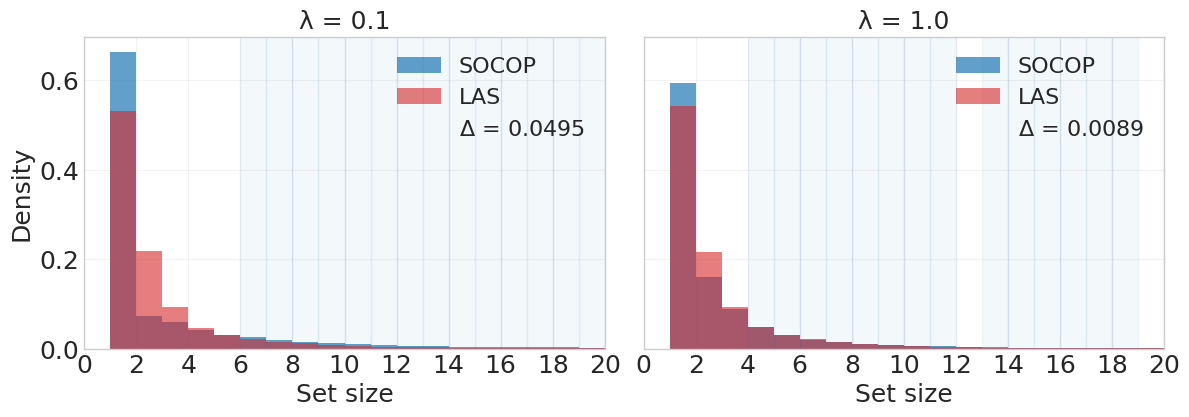

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.ticker import MaxNLocator

size_list_dir = "size_list"
seed_lambda = {2: 0.1, 3: 1.0}
seeds = [2, 3]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, seed in zip(axes, seeds):
    lam = seed_lambda[seed]
    combined_path = os.path.join(size_list_dir, f"size_list_combined-optimization-convex-hull_seed{seed}.npy")
    length_path   = os.path.join(size_list_dir, f"size_list_length-optimization_seed{seed}.npy")

    if not (os.path.exists(combined_path) and os.path.exists(length_path)):
        ax.text(0.5, 0.5, f"Missing files for seed{seed}", ha="center", va="center",
                transform=ax.transAxes, fontsize=10)
        ax.set_title(f"seed{seed} (λ={lam})", fontsize=18)
        print(f"Skipping seed={seed}, data files not found.")
        continue

    combined = np.load(combined_path).astype(int)
    length   = np.load(length_path).astype(int)
    print(f"\n--- Seed={seed} (λ={lam}) ---")

    if len(combined) == 0 or len(length) == 0:
        print("Empty data, skip this seed.")
        continue
    max_k = int(max(combined.max(), length.max()))
    pmf_SOCOP = np.bincount(combined, minlength=max_k+1)
    pmf_len  = np.bincount(length,   minlength=max_k+1)
    pmf_SOCOP = pmf_SOCOP / pmf_SOCOP.sum()
    pmf_len  = pmf_len  / pmf_len.sum()

    dominant = pmf_SOCOP > pmf_len
    for v in (0, 1):
        if v <= max_k:
            dominant[v] = False

    P_SOCOP   = pmf_SOCOP[dominant].sum()
    P_len    = pmf_len[dominant].sum()
    delta_pos = (pmf_SOCOP[dominant] - pmf_len[dominant]).sum()

    print("Results (full support, integer pmf, exclude {0,1}):")
    print(f"  > P_SOCOP (dominant excl 0,1): {P_SOCOP:.6f}")
    print(f"  > P_len  (dominant excl 0,1): {P_len:.6f}")
    print(f"  > Δ_+ = P_SOCOP - P_len:       {delta_pos:.6f}")

    bin_edges = np.arange(0, max_k+2)  

    ax.hist(combined, bins=bin_edges, density=True, alpha=0.7,
             label="SOCOP", color="tab:blue", lw=0.3)
    ax.hist(length,   bins=bin_edges, density=True, alpha=0.6,
             label="LAS", color="tab:red", lw=0.3)

    for i in np.where(dominant)[0]:
        ax.axvspan(bin_edges[i], bin_edges[i+1], alpha=0.05, color="tab:blue")

    ax.set_xlim(0, 20)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f"λ = {lam}", fontsize=18)
    ax.set_xlabel("Set size", fontsize=18)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', which='major', labelsize=18)

    handles, labels = ax.get_legend_handles_labels()
    handles.append(plt.Line2D([], [], color="none"))
    labels.append(f"$\\Delta$ = {delta_pos:.4f}")
    ax.legend(handles, labels, fontsize=16, frameon=False, loc="upper right")

axes[0].set_ylabel("Density", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.95])
os.makedirs(size_list_dir, exist_ok=True)
fig.savefig("size_list_comparison.pdf")
plt.show()


# Figure 4: Primal and Dual Geometric Views.

Parameters used for visualization:
Number of classes K = 10
Sorted probabilities p(y_i|x): [0.202 0.172 0.157 0.143 0.127 0.077 0.057 0.031 0.027 0.007]
Lambda (λ) = 0.1



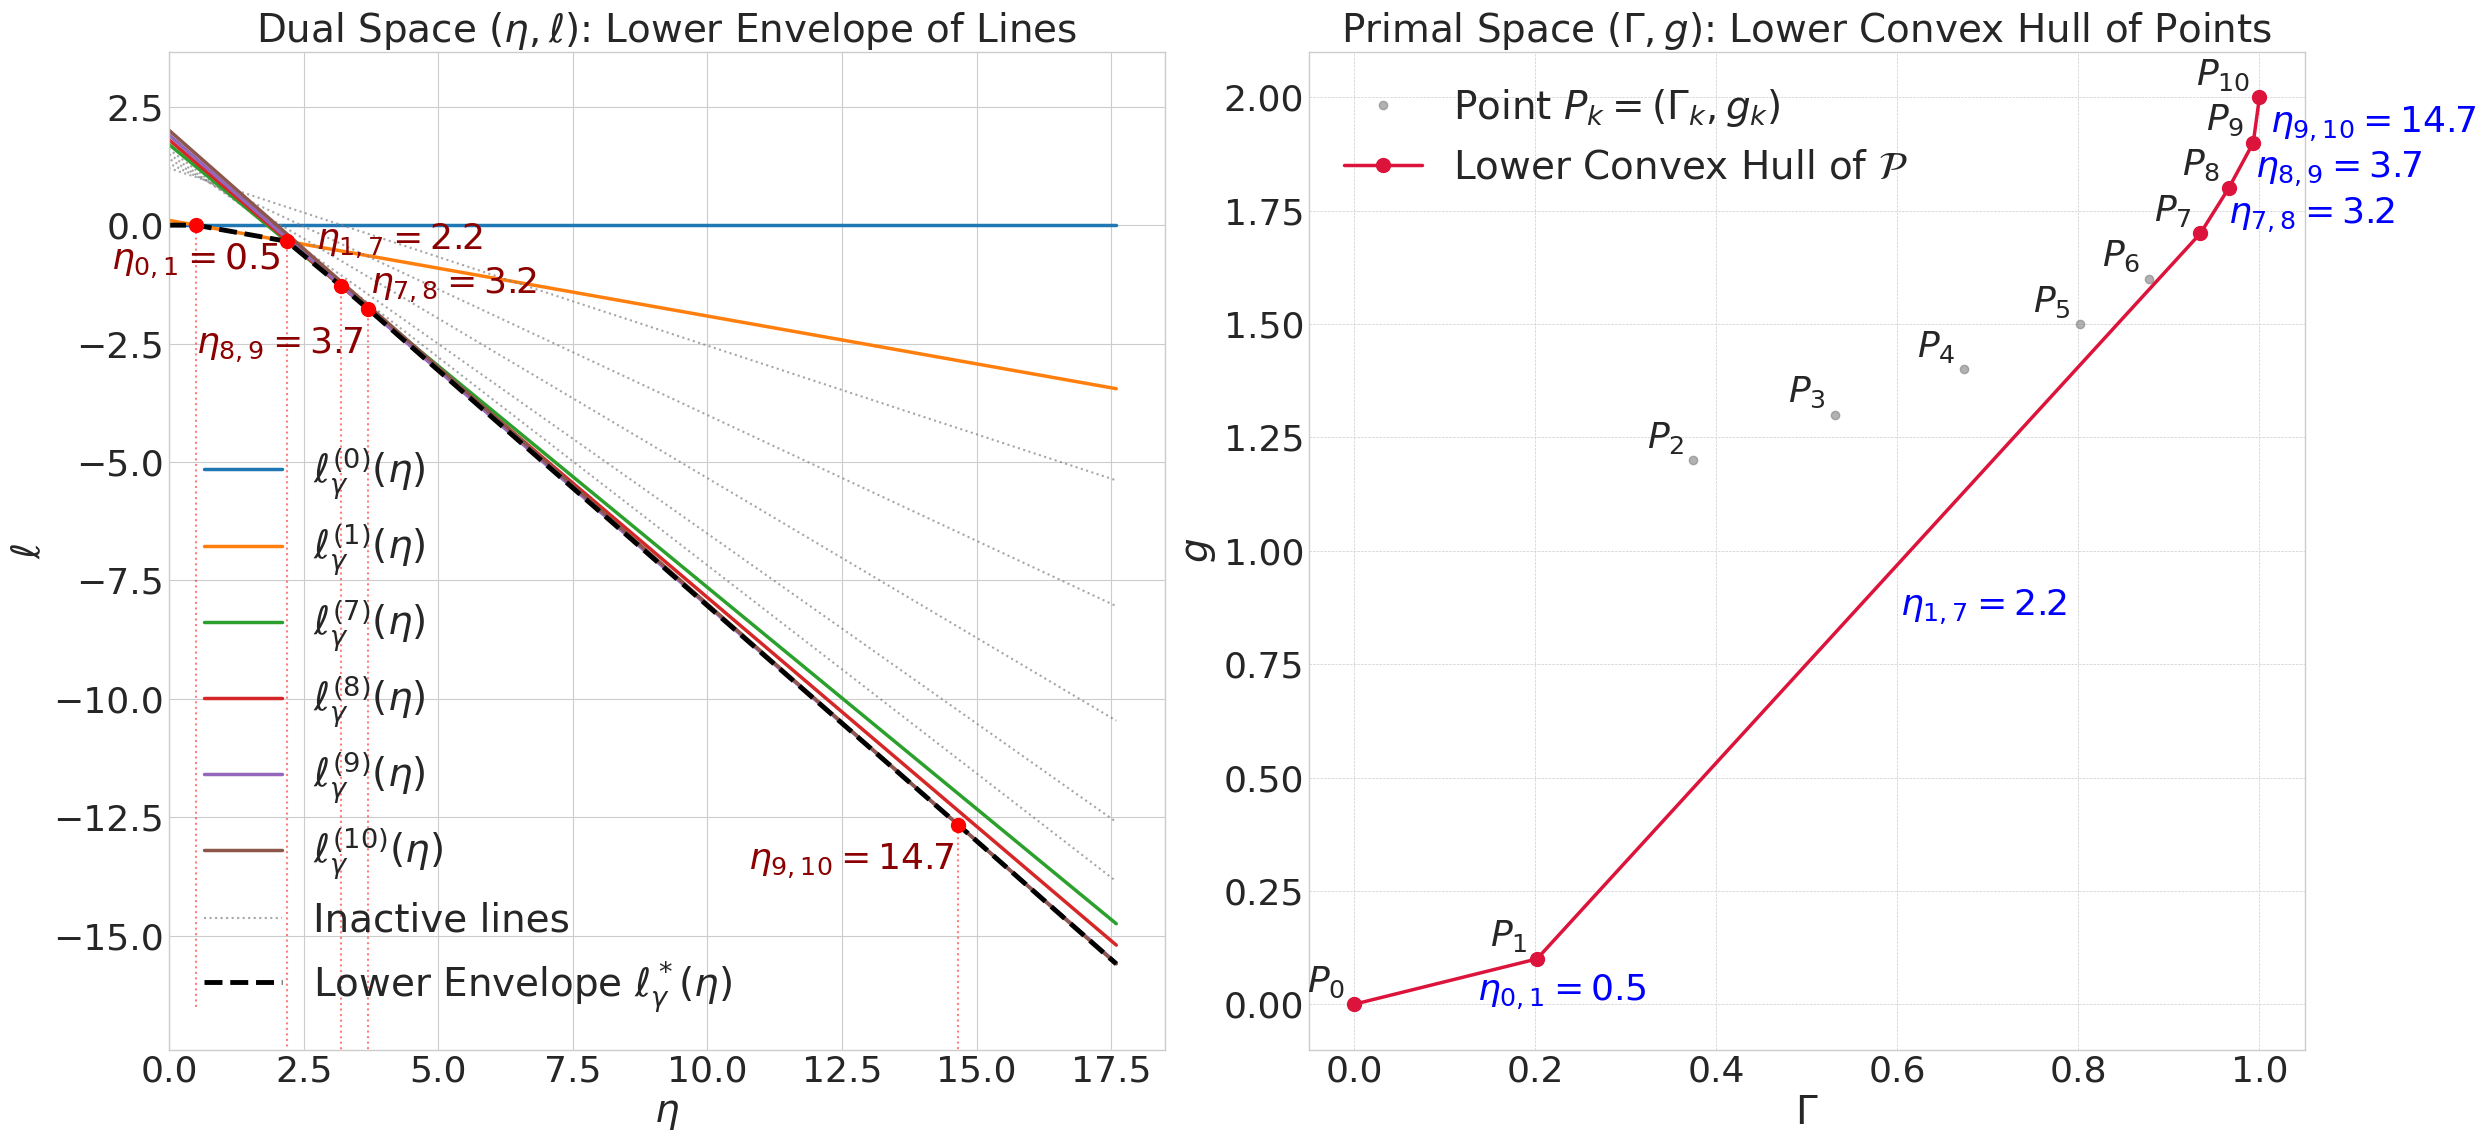

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text


def dual_visualization_with_adjusttext(probs, lambda_param):
    """
    Generates plots for dual and primal spaces with customized label placement.
    """

    K = len(probs)
    S = np.concatenate(([0], np.cumsum(probs)))
    g_k = np.array([g(k, lambda_param) for k in range(K + 1)])
    points = np.vstack((S, g_k)).T
    hull_indices = compute_lower_convex_hull(points)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(25, 12))
    plt.style.use('seaborn-v0_8-whitegrid')
    transitions = {}
    for i in range(1, len(hull_indices)):
        k_old_idx, k_new_idx = hull_indices[i-1], hull_indices[i]
        mu_transition = (g_k[k_new_idx] - g_k[k_old_idx]) / (S[k_new_idx] - S[k_old_idx])
        transitions[mu_transition] = (k_new_idx, k_old_idx)
    transition_mus = sorted(transitions.keys())
    mu_max = transition_mus[-1] * 1.2 if transition_mus else 5
    mus = np.linspace(-0.5, mu_max, 500)
    objectives = np.zeros((K + 1, len(mus)))
    for k in range(K + 1):
        objectives[k, :] = g_k[k] - mus * S[k]
        if k in hull_indices:
            label = fr'$\ell^{{({k})}}_\gamma(\eta)$'
            ax1.plot(mus, objectives[k, :],
                     linestyle='-', linewidth=2.5,
                     label=label)
        else:
            ax1.plot(mus, objectives[k, :],
                     linestyle=':', color='gray', alpha=0.7,
                     label=None)
    ax1.plot([], [], linestyle=':', color='gray', alpha=0.7, label='Inactive lines')

    lower_envelope = np.min(objectives, axis=0)
    ax1.plot(mus, lower_envelope, color='black', linewidth=3.5, linestyle='--', 
             label='Lower Envelope $\ell^*_\gamma(\eta)$')

    y_range = np.max(objectives) - np.min(lower_envelope)
    y_offset = y_range * 0.02
    x_range = mus.max() - mus.min()
    x_offset = x_range * 0.03    
    x_offset_1 = x_range * 0.005 

    for i, mu_t in enumerate(transition_mus):
        k_new, k_old = transitions[mu_t]
        ell_t = g_k[k_new] - mu_t * S[k_new]
        ax1.plot(mu_t, ell_t, 'ro', markersize=10, zorder=10)
        ax1.vlines(mu_t, ymin=ax1.get_ylim()[0], ymax=ell_t,
                   color='red', linestyle=':', alpha=0.5)

        if i == 0:
            ax1.text(mu_t, ell_t - y_offset,
                     f'$\\eta_{{{k_old},{k_new}}}={mu_t:.1f}$',
                     ha='center', va='top',
                     fontsize=26, color='darkred')
        elif i >= len(transition_mus) - 2:
            ax1.text(mu_t - x_offset_1, ell_t - y_offset,
                     f'$\\eta_{{{k_old},{k_new}}}={mu_t:.1f}$',
                     ha='right', va='top',
                     fontsize=26, color='darkred')
        else:
            ax1.text(mu_t + x_offset, ell_t,
                     f'$\\eta_{{{k_old},{k_new}}}={mu_t:.1f}$',
                     ha='left', va='center',
                     fontsize=26, color='darkred')

    ax1.set_xlabel('$\eta$', fontsize=28)
    ax1.set_ylabel('$\ell$', fontsize=28)
    ax1.set_title('Dual Space $(\eta, \ell)$: Lower Envelope of Lines', fontsize=28)
    ax1.legend(fontsize=28)
    ax1.set_ylim(bottom=np.min(lower_envelope) - y_range * 0.1)
    ax1.set_xlim(left=0)
    ax1.tick_params(axis='both', which='major', labelsize=26)


    hull_points = points[hull_indices]

    ax2.plot(points[:, 0], points[:, 1], 'o', color='gray', markersize=6, alpha=0.6,
             label='Point $P_k = (\\Gamma_k, g_k)$')
    ax2.plot(hull_points[:, 0], hull_points[:, 1], 'o-', color='crimson',
             linewidth=2.5, markersize=10, label='Lower Convex Hull of $\\mathcal{P}$')

    for i in range(K + 1):
        fontweight = 'bold' if i in hull_indices else 'normal'
        ax2.text(points[i, 0] - 0.01,
                 points[i, 1] + 0.01,
                 f'$P_{{{i}}}$',
                 ha='right', va='bottom',
                 fontsize=26, fontweight=fontweight)

    x_range = np.ptp(points[:, 0])
    y_range = np.ptp(points[:, 1])

    for i in range(len(hull_indices) - 1):
        p1_idx, p2_idx = hull_indices[i], hull_indices[i+1]
        p1, p2 = points[p1_idx], points[p2_idx]
        mid = (p1 + p2) / 2.0
        eta = (p2[1] - p1[1]) / (p2[0] - p1[0])

        if i < 2:
            text_pos = (mid[0] + 0.035 * x_range,
                        mid[1] - 0.012 * y_range)
        else:
            text_pos = (mid[0] + 0.015 * x_range,
                        mid[1] - 0.005 * y_range)

        ax2.text(text_pos[0], text_pos[1],
                f'$\\eta_{{{p1_idx},{p2_idx}}}={eta:.1f}$',
                fontsize=26, color='blue',
                ha='left', va='center')

    ax2.set_xlabel('$\\Gamma$', fontsize=28)
    ax2.set_ylabel('$g$', fontsize=28)
    ax2.set_title('Primal Space $(\\Gamma, g)$: Lower Convex Hull of Points', fontsize=28)
    ax2.legend(fontsize=28, loc='upper left')
    ax2.grid(True, which='both', linestyle='--', linewidth=0.5)
    ax2.tick_params(axis='both', which='major', labelsize=26)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    fig.savefig("primal_dual.pdf")

# --- Example Execution ---
K_classes = 10
np.random.seed(43)
base_probs = np.random.rand(K_classes)
probs_vec = np.sort(base_probs)[::-1]
probs_vec /= np.sum(probs_vec)
lambda_parameter = 0.1

print("Parameters used for visualization:")
print(f"Number of classes K = {K_classes}")
print("Sorted probabilities p(y_i|x):", np.round(probs_vec, 3))
print(f"Lambda (λ) = {lambda_parameter}\n")

dual_visualization_with_adjusttext(probs_vec, lambda_parameter)


# Figure 5: Optimal Set Size $\kappa(\eta ; \gamma)$

Parameters used for visualization:
Number of classes K = 10
Sorted probabilities p(y_i|x): [0.202 0.172 0.157 0.143 0.127 0.077 0.057 0.031 0.027 0.007]
Lambda (λ) = 0.1



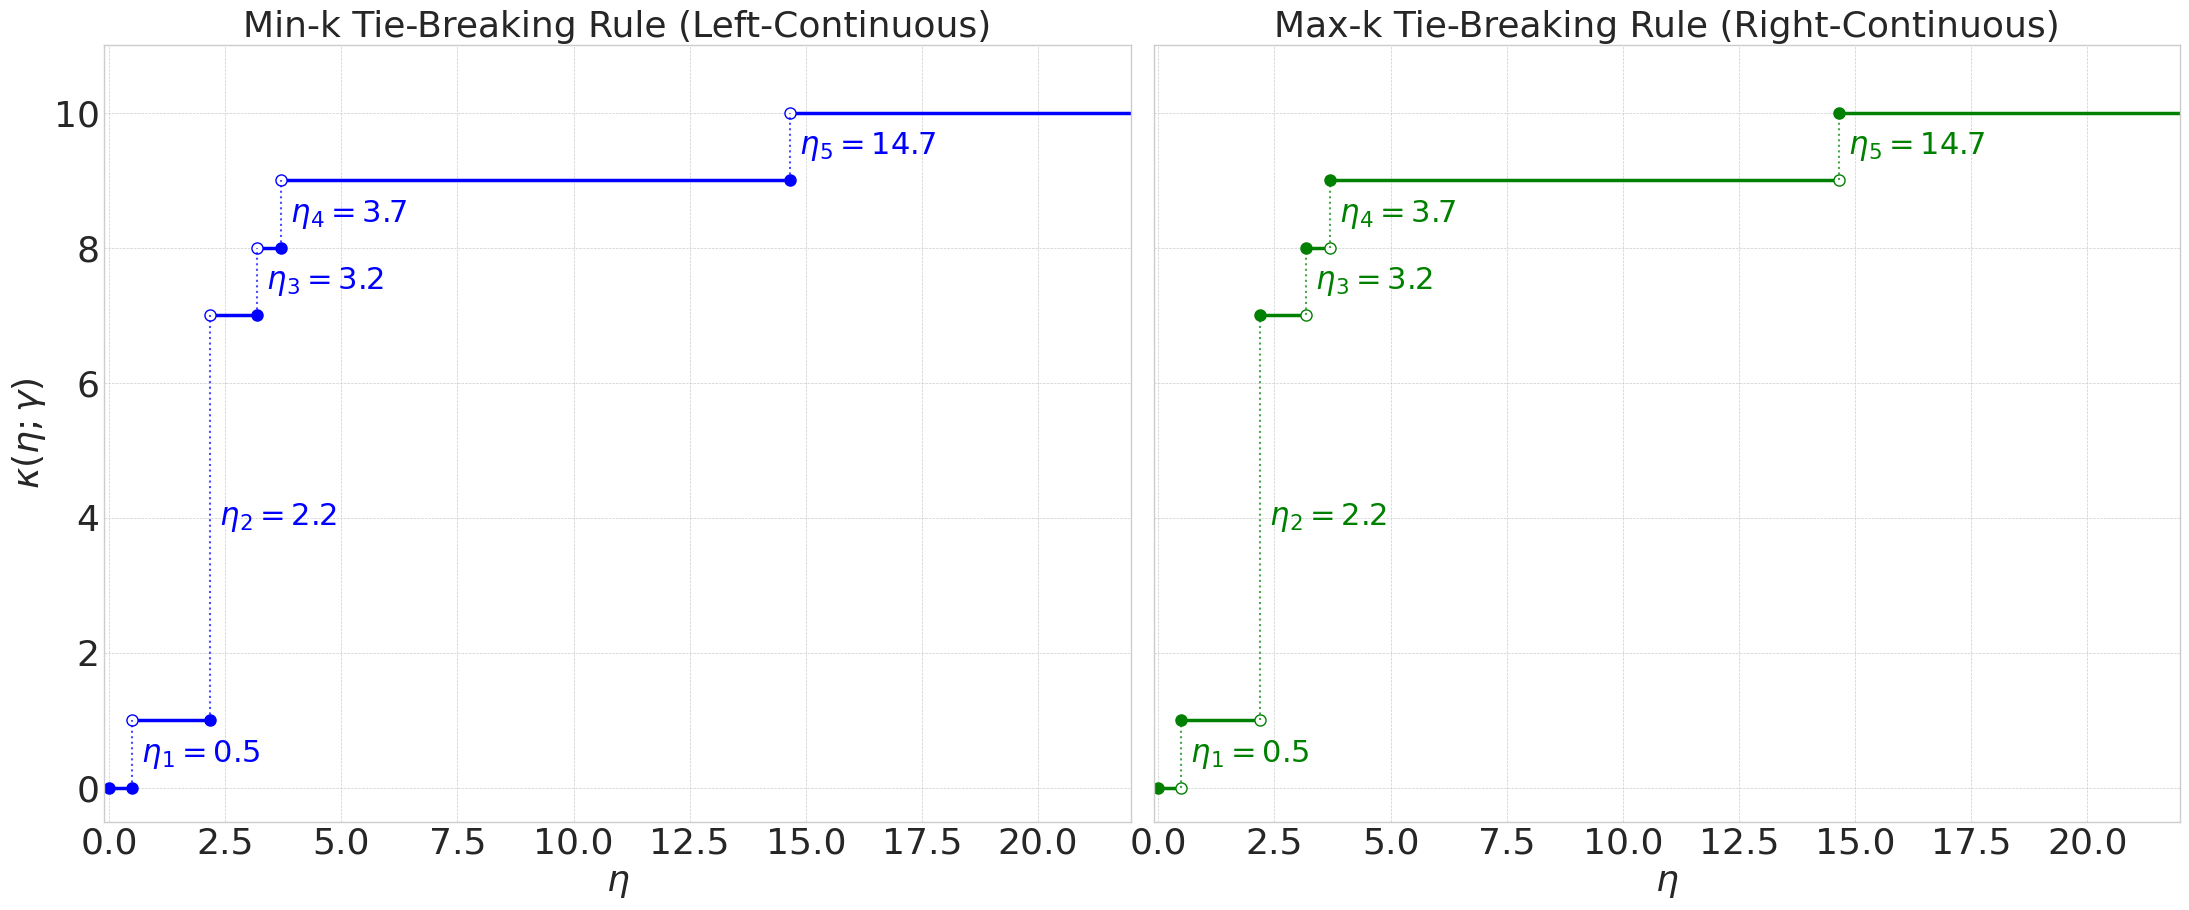

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def plot_k_mu_step_function_final(probs, lambda_param):
    """
    Visualizes k(μ) with code structure that explicitly matches the three-part
    mathematical definition for both tie-breaking rules.
    """
    K = len(probs)
    S = np.concatenate(([0], np.cumsum(probs)))
    g_k = np.array([g(k, lambda_param) for k in range(K + 1)])
    points = np.vstack((S, g_k)).T

    v = compute_lower_convex_hull(points) 
    m = len(v) - 1
    
    if m == 0:
        mus = [0.0]
    else:
        mus = [0.0] + [
            (g_k[v[i]] - g_k[v[i-1]]) / (S[v[i]] - S[v[i-1]])
            for i in range(1, m + 1)
        ]
    mu_max_plot = mus[-1] * 1.5 if m > 0 else 5

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 10), sharey=True)

    ax1.set_title('Min-k Tie-Breaking Rule (Left-Continuous)', fontsize=26)
    
    if m > 0:
        ax1.plot([0, mus[1]], [v[0], v[0]], 'b-', lw=2.5)
        ax1.plot(0, v[0], 'o', mec='b', mfc='b', ms=8)      
        ax1.plot(mus[1], v[0], 'o', mec='b', mfc='b', ms=8)  
        
        for i in range(1, m):
            mu_i, mu_i_plus_1 = mus[i], mus[i+1]
            k_val = v[i]
            ax1.plot([mu_i, mu_i_plus_1], [k_val, k_val], 'b-', lw=2.5)
            ax1.plot(mu_i, k_val, 'o', mec='b', mfc='w', ms=8)          
            ax1.plot(mu_i_plus_1, k_val, 'o', mec='b', mfc='b', ms=8)   
        
        ax1.plot([mus[m], mu_max_plot], [v[m], v[m]], 'b-', lw=2.5)
        ax1.plot(mus[m], v[m], 'o', mec='b', mfc='w', ms=8) 

        for i in range(1, m + 1):
            ax1.vlines(mus[i], ymin=v[i-1], ymax=v[i], color='b', linestyle=':', alpha=0.7)
            ax1.text(mus[i], (v[i-1] + v[i]) / 2, f' $\eta_{i}={mus[i]:.1f}$', color='b', ha='left', va='center', fontsize=22)
    else: 
        ax1.plot([0, mu_max_plot], [v[0], v[0]], 'b-', lw=2.5)

    ax2.set_title('Max-k Tie-Breaking Rule (Right-Continuous)', fontsize=26)
    
    if m > 0:
        ax2.plot([0, mus[1]], [v[0], v[0]], 'g-', lw=2.5)
        ax2.plot(0, v[0], 'o', mec='g', mfc='g', ms=8)     
        ax2.plot(mus[1], v[0], 'o', mec='g', mfc='w', ms=8) 

        for i in range(1, m):
            mu_i, mu_i_plus_1 = mus[i], mus[i+1]
            k_val = v[i]
            ax2.plot([mu_i, mu_i_plus_1], [k_val, k_val], 'g-', lw=2.5)
            ax2.plot(mu_i, k_val, 'o', mec='g', mfc='g', ms=8)          
            ax2.plot(mu_i_plus_1, k_val, 'o', mec='g', mfc='w', ms=8)   
            
        ax2.plot([mus[m], mu_max_plot], [v[m], v[m]], 'g-', lw=2.5)
        ax2.plot(mus[m], v[m], 'o', mec='g', mfc='g', ms=8) 

        for i in range(1, m + 1):
            ax2.vlines(mus[i], ymin=v[i-1], ymax=v[i], color='g', linestyle=':', alpha=0.7)
            ax2.text(mus[i], (v[i-1] + v[i]) / 2, f' $\eta_{i}={mus[i]:.1f}$', color='g', ha='left', va='center', fontsize=22)
    else: 
        ax2.plot([0, mu_max_plot], [v[0], v[0]], 'g-', lw=2.5)

    for ax in [ax1, ax2]:
        ax.set_xlabel('$\eta$', fontsize=26)
        ax.grid(True, which='both', linestyle='--', linewidth=0.5)
        max_k_val = max(v) if v else 0
        ax.set_yticks(np.arange(0, max_k_val + 2, step=max(1, max_k_val // 5)))
        ax.set_xlim(left=-0.1, right=mu_max_plot)
        ax.set_ylim(bottom=-0.5, top=max_k_val + 1)
        ax.tick_params(axis='both', which='major', labelsize=26)
    
    ax1.set_ylabel('$\kappa(\eta;\gamma)$', fontsize=26)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    fig.savefig("k_mu_step_function.pdf")

# --- Main Execution ---
K_classes = 10
np.random.seed(43)
base_probs = np.random.rand(K_classes)
probs_vec = np.sort(base_probs)[::-1]
probs_vec /= np.sum(probs_vec)
lambda_parameter = 0.1

print("Parameters used for visualization:")
print(f"Number of classes K = {K_classes}")
print("Sorted probabilities p(y_i|x):", np.round(probs_vec, 3))
print(f"Lambda (λ) = {lambda_parameter}\n")

plot_k_mu_step_function_final(probs_vec, lambda_parameter)